# **How to Run MegaDetector: A Practical Workflow**

The MegaDetector was employed to automatically eliminate blank images from the camera trap dataset. Since MegaDetector only performs animal detection without providing species-level identification, a custom YOLO11 model was integrated, specifically trained for species classification. This workflow enables the combination of both approaches: efficient blank image removal with MegaDetector and accurate species identification with YOLO11.

The description of MegaDetector’s functionality was based on the official documentation available at
[MegaDetector](https://github.com/agentmorris/MegaDetector/tree/main)

In [ ]:
#Required libraries
!pip install humanfriendly jsonpickle ultralytics

##Required resources

In [ ]:
!rm -rf /content/MegaDetector
!rm -rf /content/yolov5
!git clone https://github.com/ecologize/yolov5/ /content/yolov5
!git clone https://github.com/agentmorris/MegaDetector /content/MegaDetector

##Environment variables

In [ ]:
import os
os.environ['PYTHONPATH'] += ":/content/MegaDetector"
os.environ['PYTHONPATH'] += ":/content/yolov5"

## Run the detection script

The run_detector_batch.py script requires three mandatory arguments:

1.   MegaDetector model file (either a model name, e.g., "MDV5A", or a path to a model file).
2.   Image folder (directory containing the images to be processed).
3.   Output JSON file location and name.




In [ ]:
#Script for batch image processing
!python /content/MegaDetector/megadetector/detection/run_detector_batch.py "MDV5A" "/content/img" "/content/teste.json" --threshold 0.5

In [ ]:
#Script for single-image processing
!python /content/MegaDetector/megadetector/detection/run_detector.py "MDV5" --image_file "image_file" --threshold 0.70 --output_dir "/content/teste"

The process_video.py script from MegaDetector requires two mandatory arguments:


1.   Model file (model_file) – this can be either a model name (e.g., "MDV5A") or the path to a MegaDetector model file (.pt or .pb). You can also use "no_detection" if you only want to extract video frames without running detection.

1.   Input video file (input_video_file) – the video (or folder of videos) to be processed.




In [ ]:
!python /content/MegaDetector/megadetector/detection/process_video.py "MDV5A" "/content/01010025_1.mp4" --output_json_file "/content/teste_video/test_output.json" --json_confidence_threshold 0.8

Model v5a.0.1 already exists and is valid at /tmp/megadetector_models/md_v5a.0.1.pt
PyTorch reports 1 available CUDA devices (load_detector)
/content/yolov5/utils/general.py:31: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg
Loading PT detector with compatibility mode classic
Loaded image size 1280 from model metadata
Using model stride: 64
Detection categories (MegaDetector class names from model file, class IDs offset by 1): {'1': 'animal', '2': 'person', '3': 'vehicle'}
PTDetector using device cuda:0
Fusing layers... 
Model summary: 574 layers, 139990096 parameters, 0 gradients, 207.9 GFLOPs
Processing 1 videos from folder /content
Processing video: 100% 1/1 [00:19<00:00, 19.91s/it]
Finished running MD on videos
Model v5a.0.1 already exists and is valid at /tmp/

# Visualization

In [ ]:
import cv2
import os

In [ ]:
# Annotate images from the MegaDetector JSON
# - Supports normalized bbox [x, y, w, h] (0..1) or absolute (in pixels)
# - Searches for images by basename in the specified root directory
# - Keeps the original filename in the output
import os, json, cv2

# ==== CONFIGURE HERE ====
json_path        = "/content/teste.json"
images_root_dir  = "/content/img"
out_dir          = "/content/teste/annotated_images"
min_conf         = 0.05     # draw only detections with conf >= min_conf
draw_label       = True
# ========================

os.makedirs(out_dir, exist_ok=True)

# Utility: index images by basename (lowercase) for fast lookup
def build_image_index(root_dir):
    index = {}
    exts = {".jpg",".jpeg",".png",".bmp",".tif",".tiff",".webp",".gif"}
    for r,_,files in os.walk(root_dir):
        for f in files:
            if os.path.splitext(f)[1].lower() in exts:
                index[f.lower()] = os.path.join(r, f)
    return index

img_index = build_image_index(images_root_dir)
print(f"Indexed {len(img_index)} images in '{images_root_dir}'.")

# Load JSON
with open(json_path, "r") as f:
    jd = json.load(f)

cat_map = jd.get("detection_categories", {"1":"animal","2":"person","3":"vehicle"})
images = jd.get("images", [])
if not images:
    raise RuntimeError("JSON without an 'images' key. Check MegaDetector's output format.")

def bbox_to_abs(bbox, W, H):
    """ Converts normalized [x, y, w, h] (0..1) to pixels; if already in pixels, keeps as is."""
    x, y, w, h = bbox
    if max(x, y, w, h) <= 1.0:
        X, Y, WW, HH = int(x*W), int(y*H), int(w*W), int(h*H)
    else:
        X, Y, WW, HH = int(x), int(y), int(w), int(h)
    # limit to image
    X = max(0, min(X, W-1)); Y = max(0, min(Y, H-1))
    WW = max(1, min(WW, W - X)); HH = max(1, min(HH, H - Y))
    return X, Y, WW, HH

processed, drawn_boxes, missing_imgs = 0, 0, 0

for im in images:
    file_in_json = im.get("file") or im.get("image_path") or ""
    base = os.path.basename(file_in_json).lower()
    src = None

    # 1) if the path in the JSON actually exists, use it
    if os.path.exists(file_in_json):
        src = file_in_json
    else:
        # 2) try to locate by index (basename) inside the root folder
        src = img_index.get(base)

    if not src or not os.path.exists(src):
        missing_imgs += 1
        # print(f" Image not found: {file_in_json}")
        continue

    img = cv2.imread(src)
    if img is None:
        missing_imgs += 1
        # print(f" Failed to open: {src}")
        continue

    H, W = img.shape[:2]
    # thickness proportional to size
    thickness = max(2, round(min(H, W)/500))
    font_scale = 0.6 if min(H, W) >= 600 else 0.5

    for det in im.get("detections", []):
        conf = float(det.get("conf", det.get("confidence", det.get("score", 0.0))))
        if conf < min_conf:
            continue
        bbox = det.get("bbox") or det.get("rect") or det.get("box")
        if not bbox:
            continue

        X, Y, WW, HH = bbox_to_abs(bbox, W, H)
        cv2.rectangle(img, (X, Y), (X+WW, Y+HH), (0, 255, 0), thickness)

        if draw_label:
            cat = cat_map.get(str(det.get("category","1")), str(det.get("category","1")))
            label = f"{cat} {conf:.2f}"
            # shadow for readability
            cv2.putText(img, label, (X, max(0, Y-6)),
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0,0,0), thickness, cv2.LINE_AA)
            cv2.putText(img, label, (X, max(0, Y-6)),
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0,255,0), max(1, thickness-1), cv2.LINE_AA)

        drawn_boxes += 1

    out_path = os.path.join(out_dir, os.path.basename(src))
    # out_path = os.path.splitext(out_path)[0] + ".jpg"
    cv2.imwrite(out_path, img)
    processed += 1

print(f"✅ Done! Images processed: {processed} | Boxes drawn: {drawn_boxes} | Not found: {missing_imgs}")
print(f"Output in: {out_dir}")


Indexed 4 images in '/content/img'.
✅ Done! Images processed: 4 | Boxes drawn: 4 | Not found: 0
Output in: /content/teste/annotated_images


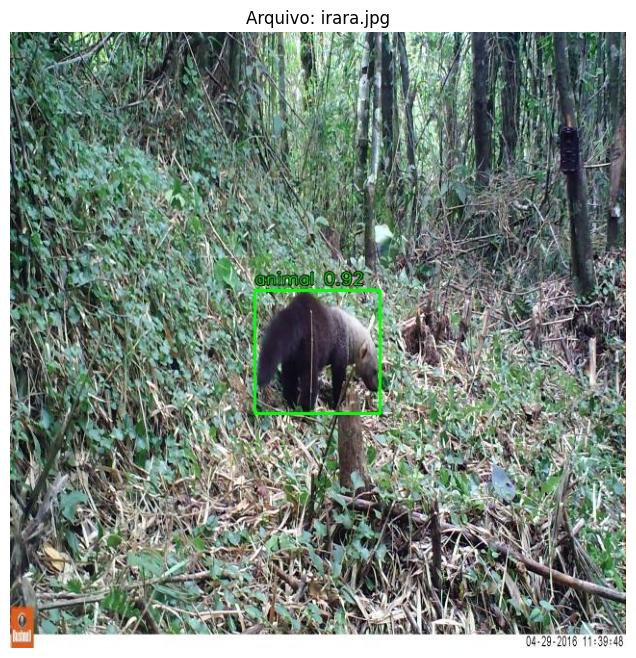

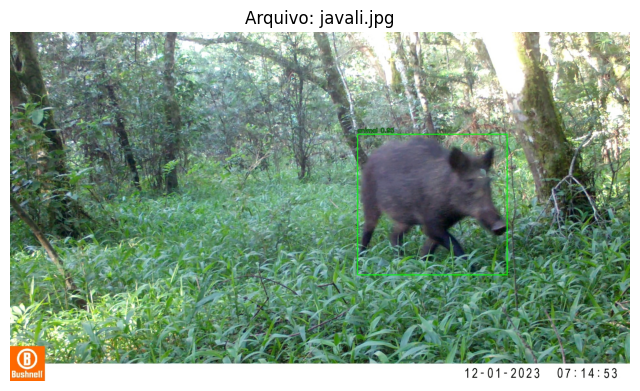

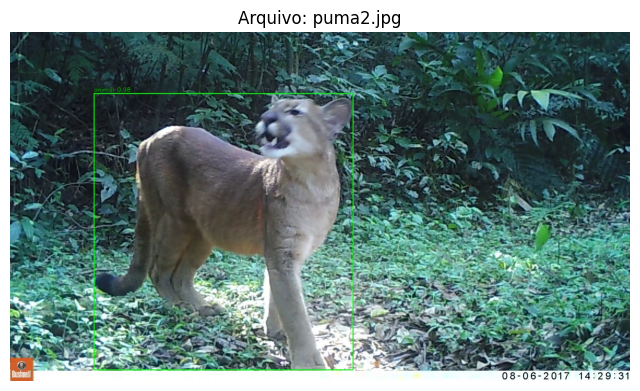

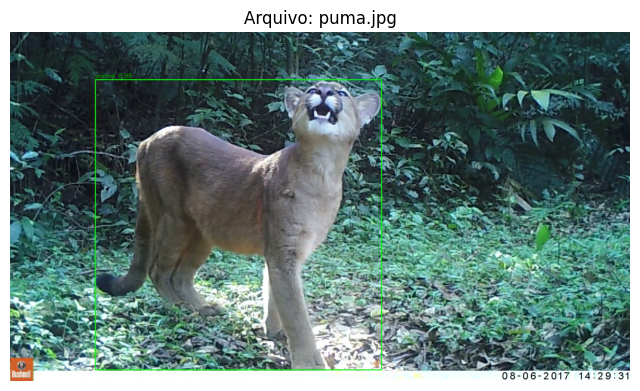

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import glob

image_paths = glob.glob("/content/teste/annotated_images/*.jpg") + glob.glob("/content/teste/img/*.png")

for path in image_paths:
    img = Image.open(path)
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.title(f"Arquivo: {path.split('/')[-1]}")
    plt.axis("off")
    plt.show()

In [ ]:
# Draws filtered JSON bounding boxes and labels onto video frames and saves the output video.
import os, json, cv2


json_path  = "/content/teste_video/test_output.json"
video_path = "/content/01010025_1.mp4"
out_path   = "/content/01010025_2.mp4"
min_conf   = 0.08

os.makedirs(os.path.dirname(out_path), exist_ok=True)

# ---- JSON (format: images[0].detections with frame_number) ----
with open(json_path, "r") as f:
    jd = json.load(f)

imgs = jd.get("images", [])
if not imgs or "detections" not in imgs[0]:
    raise RuntimeError("Unexpected JSON: expected images[0].detections com frame_number.")

det_list = imgs[0]["detections"]
frame_rate_json = imgs[0].get("frame_rate", None)
cat_map = jd.get("detection_categories", {"1":"animal","2":"person","3":"vehicle"})

# frame_idx -> [det, ...]
frame_map = {}
for d in det_list:
    conf = float(d.get("conf", d.get("confidence", d.get("score", 0))))
    if conf < min_conf:
        continue
    fi = int(d["frame_number"])
    frame_map.setdefault(fi, []).append(d)

# ---- writer ----
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeError(f"Failed to open video: {video_path}")

W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
if not fps or fps <= 0:
    fps = frame_rate_json or 25.0

def bbox_to_abs(bbox, W, H):
    x, y, w, h = bbox
    if max(x, y, w, h) <= 1.0:
        return int(x*W), int(y*H), int(w*W), int(h*H)
    return int(x), int(y), int(w), int(h)

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(out_path, fourcc, fps, (W, H))
if not writer.isOpened():
    # fallback AVI/MJPG
    alt = os.path.splitext(out_path)[0] + ".avi"
    writer = cv2.VideoWriter(alt, cv2.VideoWriter_fourcc(*"MJPG"), fps, (W, H))
    if not writer.isOpened():
        raise RuntimeError("Failed to open VideoWriter (try another path/codec).")
    out_path = alt
    print(f" MP4 unavailable; saving as AVI/MJPG: {out_path}")

# ---- render ----
drawn = 0
frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    for d in frame_map.get(frame_idx, []):
        X, Y, WW, HH = bbox_to_abs(d["bbox"], W, H)
        cv2.rectangle(frame, (X, Y), (X+WW, Y+HH), (0,255,0), 2)
        cat = cat_map.get(str(d.get("category","1")), "obj")
        conf = float(d.get("conf", d.get("confidence", d.get("score", 0))))
        cv2.putText(frame, f"{cat} {conf:.2f}", (X, max(0, Y-6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2, cv2.LINE_AA)
        drawn += 1
    writer.write(frame)
    frame_idx += 1

cap.release()
writer.release()
print(f" Generated: {out_path} | Bounding boxes: {drawn} | Frames: {frame_idx}")


 Generated: /content/01010025_2.mp4 | Bounding boxes: 102 | Frames: 102


In [ ]:
from IPython.display import HTML
from base64 import b64encode
import os
import subprocess
# Input video path
save_path = '/content/01010025_2.mp4'

# Compressed video path
compressed_path = "/content/01010025_3.mp4"

subprocess.run([
    'ffmpeg','-y','-i', save_path,
    '-c:v','libx264','-crf','23','-preset','veryfast',
    '-c:a','aac','-b:a','128k',
    '-movflags','+faststart','-pix_fmt','yuv420p',
    compressed_path
], check=True)

with open(compressed_path, 'rb') as f:
    mp4 = f.read()

data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f"""
<video width="800" controls>
  <source src="{data_url}" type="video/mp4">
</video>
""")

# **Using YOLO11 Custom: Step-by-Step Instructions**

A custom YOLO11 model was used for species-level classification. YOLO11, developed by Ultralytics, is a modern object detection architecture that combines accuracy, speed, and efficiency.

For more information, see the official documentation:[Ultralytics YOLO11](https://docs.ultralytics.com/pt/models/yolo11/)


The model was trained with images from the Mixed Ombrophilous Forest (Araucaria Forest) and from areas of dense Araucaria forest, both within the Atlantic Forest biome.

In [ ]:
!pip install ultralytics

In [ ]:
import ultralytics
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
ultralytics.checks()

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.7/112.6 GB disk)


The structure shown below can point either to a folder of images or to a single image file.
The same logic applies to videos: it can represent a folder of videos or a single video file.

In [ ]:
MODEL_PATH = "/content/best.pt"  # Model path
DATA_IMAGES_DIR = "/content/img"
DATA_VIDEOS_DIR = "/content/01010025_1.mp4"

In [ ]:
model = YOLO(MODEL_PATH)
print("Model-mapped classe:", model.names)

Model-mapped classe: {0: 'cachorro-do-mato', 1: 'javali', 2: 'mao-pelada', 3: 'veado', 4: 'gato-do-mato-pequeno', 5: 'gato-maracaja', 6: 'irara', 7: 'jaguarundi', 8: 'jaguatirica', 9: 'puma', 10: 'tatu'}


In [ ]:
from PIL import Image
import IPython.display as display
import os
#processing image
results = model.predict(source=DATA_IMAGES_DIR,save_json=True, save=True, save_txt= True)


out_dir = results[0].save_dir

#Builds the path of the annotated image (same name as the input inside the folder)
out_path = os.path.join(out_dir, os.path.basename(DATA_IMAGES_DIR))




image 1/4 /content/img/irara.jpg: 640x640 1 irara, 62.4ms
image 2/4 /content/img/javali.jpg: 384x640 1 javali, 103.6ms
image 3/4 /content/img/puma.jpg: 384x640 1 puma, 31.1ms
image 4/4 /content/img/puma2.jpg: 384x640 1 puma, 31.1ms
Speed: 13.1ms preprocess, 57.1ms inference, 10.2ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict
4 labels saved to /content/runs/detect/predict/labels


/content/runs/detect/predict/irara.jpg


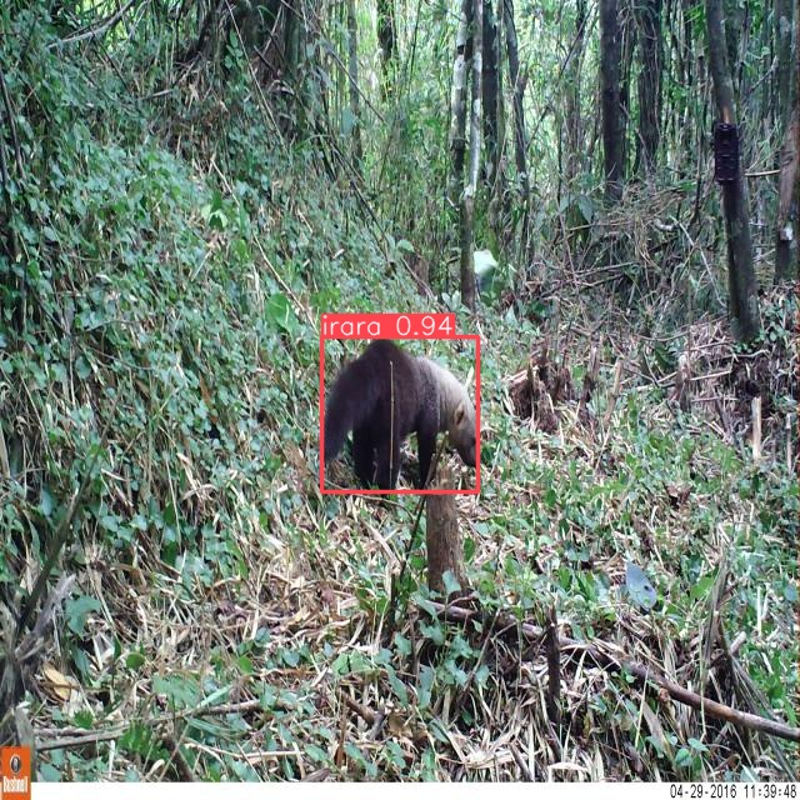

/content/runs/detect/predict/javali.jpg


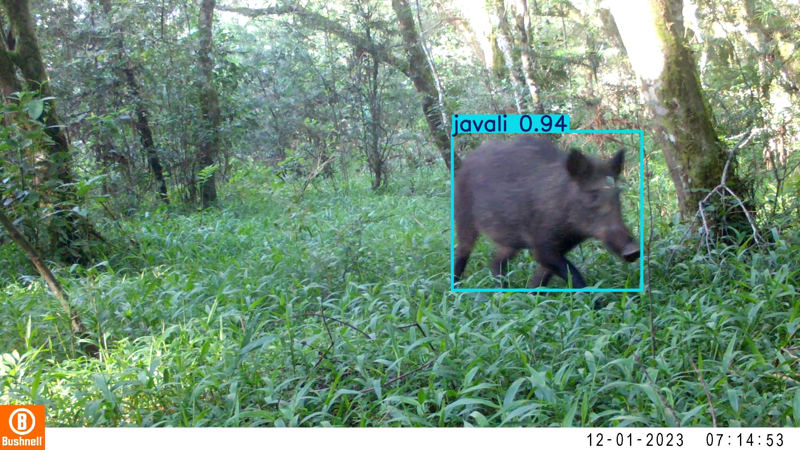

/content/runs/detect/predict/puma.jpg


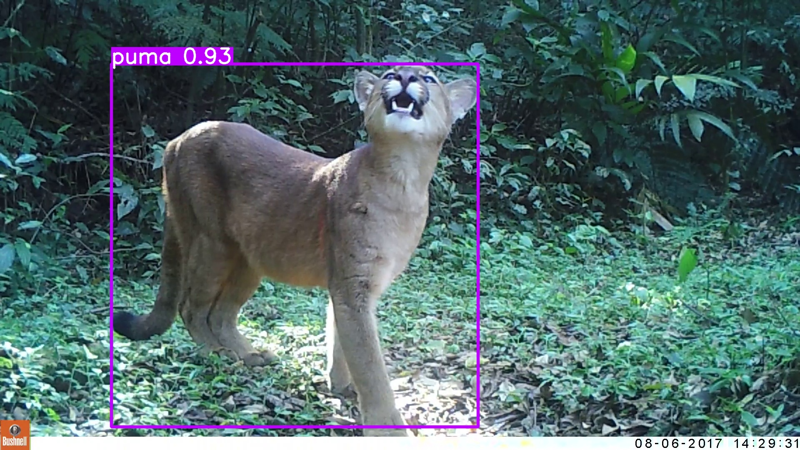

/content/runs/detect/predict/puma2.jpg


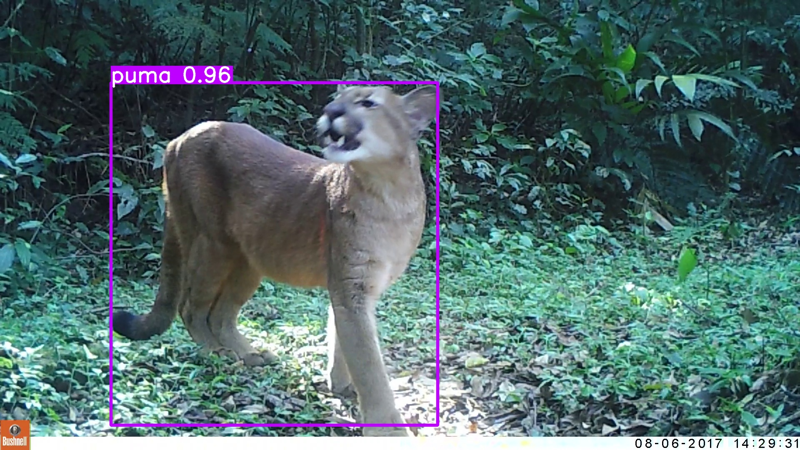

In [ ]:
import os
from PIL import Image
import IPython.display as display

pasta_base = "/content/runs/detect/predict"
extensoes = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

for raiz, _, arquivos in os.walk(pasta_base):
    for nome_arquivo in sorted(arquivos):
        if nome_arquivo.lower().endswith(extensoes):
            caminho_img = os.path.join(raiz, nome_arquivo)

            img = Image.open(caminho_img)
            img_resized = img.resize((800, int(img.height * 800 / img.width)))

            print(caminho_img)
            display.display(img_resized)

In [ ]:
#processing video
#results = model.predict(source=DATA_VIDEOS_DIR, save=True)
results = model.predict(
    source=DATA_VIDEOS_DIR,
    conf=0.9,
    save=True
)

In [ ]:
from IPython.display import HTML
from base64 import b64encode
import os
import subprocess
# Input video path
save_path = '/content/runs/detect/predict-2/01010025_1.avi'

# Compressed video path
compressed_path = "/content/teste.mp4"

subprocess.run([
    'ffmpeg','-y','-i', save_path,
    '-c:v','libx264','-crf','23','-preset','veryfast',
    '-c:a','aac','-b:a','128k',
    '-movflags','+faststart','-pix_fmt','yuv420p',
    compressed_path
], check=True)

with open(compressed_path, 'rb') as f:
    mp4 = f.read()

data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f"""
<video width="800" controls>
  <source src="{data_url}" type="video/mp4">
</video>
""")